In [3]:

from pathlib import Path
import numpy as np
import pandas as pd

# Resolve the project root
cwd = Path.cwd()

if cwd.name == "notebooks":
    project_root = cwd.parent
else:
    project_root = cwd

# Load the engineered dataset created in Step 1
DATA_PATH = project_root / "data" / "processed" / "engineered_tracks.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Engineered dataset not found at:\n{DATA_PATH.resolve()}\n"
        "Run Step 1 in feature_engineering.ipynb first."
    )

features = pd.read_csv(DATA_PATH)

print("=" * 55)
print("ENGINEERED DATASET LOADED")
print("=" * 55)
print("File:", DATA_PATH.resolve())
print("Shape:", features.shape)

print("\nFirst five rows:")
display(features.head())

print("\nColumn names:")
print(features.columns.tolist())

print("\nDuplicate track IDs:", features["track_id"].duplicated().sum())
print("=" * 55)


ENGINEERED DATASET LOADED
File: /Users/janibhargesh/Documents/ML-Project/data/processed/engineered_tracks.csv
Shape: (151598, 63)

First five rows:


,track_id,vehicle_id,tour_id,start_time,stop_time,distance,track_gap,avg_speed,max_speed,n_signal_loss,...,n_signal_loss_valid,r_signal_loss_valid,distance_km,avg_speed_kmh,max_speed_kmh,raw_speed_mean_kmh,duration_minutes,avg_speed_implausible,speed_distance_validity,signal_loss_validity
0,0,1,0,2021-09-10 11:04:53.598000+02:00,2021-09-10 12:07:57.395000+02:00,30751.0,NaN,8.13,20.58,0.0,...,0.0,0.0,30.751,29.268,74.088,28.834092,63.063283,False,valid,valid
1,1,1,0,2021-09-10 12:57:54.718000+02:00,2021-09-10 13:13:53.221000+02:00,7762.0,37.504057,8.10,21.79,0.0,...,0.0,0.0,7.762,29.160,78.444,28.411624,15.975050,False,valid,valid
2,2,1,0,2021-09-10 13:25:20.146000+02:00,2021-09-10 14:09:50.802000+02:00,19432.0,4.895394,7.28,24.75,0.0,...,0.0,0.0,19.432,26.208,89.100,25.709182,44.510933,False,valid,valid
3,3,1,1,2021-09-10 14:21:35.547000+02:00,2021-09-10 14:25:26.391000+02:00,56.0,3.836167,0.24,2.44,0.0,...,0.0,0.0,0.056,0.864,8.784,0.456291,3.847400,False,valid,valid
4,4,1,1,2021-09-10 15:39:48.925000+02:00,2021-09-10 15:45:05.392000+02:00,201.0,12.816326,0.64,3.80,0.0,...,0.0,0.0,0.201,2.304,13.680,1.745397,5.274450,False,valid,valid



Column names:
['track_id', 'vehicle_id', 'tour_id', 'start_time', 'stop_time', 'distance', 'track_gap', 'avg_speed', 'max_speed', 'n_signal_loss', 'd_signal_loss', 'r_signal_loss', 'avg_hdop', 'home_base', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'cid', 'fleet_test_id', 'gross_vehicle_weight', 'total_mass_with_trailer', 'axle_class', 'raw_observations', 'telemetry_span_seconds', 'raw_speed_mean', 'raw_speed_std', 'raw_speed_min', 'raw_speed_max', 'raw_hdop_mean', 'raw_hdop_median', 'raw_hdop_max', 'missing_speed_count', 'missing_hdop_count', 'insufficient_telemetry', 'start_time_parsed', 'stop_time_parsed', 'duration_seconds', 'duration_invalid', 'avg_speed_negative', 'avg_speed_gt_max_speed', 'raw_speed_missing', 'n_signal_loss_negative', 'r_signal_loss_missing', 'r_signal_loss_out_of_range', 'distance_missing', 'zero_distance', 'zero_distance_speed_issue', 'track_gap_missing', 'limited_telemetry', 'insufficient_core_telemetry', 'avg_speed_valid', 'max_speed_

In [4]:

# Create a separate subset for operational analysis.
# The original `features` DataFrame remains unchanged.

operational = features.loc[
    features["distance_km"] > 1
].copy()

print("=" * 55)
print("OPERATIONAL DATASET")
print("=" * 55)

print("Full dataset shape:", features.shape)
print("Operational dataset shape:", operational.shape)

print(
    "\nTracks with distance > 1 km:",
    len(operational)
)

print(
    "Tracks excluded by this filter:",
    len(features) - len(operational)
)

print(
    "\nMissing distance_km values:",
    features["distance_km"].isna().sum()
)

print(
    "Minimum operational distance (km):",
    operational["distance_km"].min()
)

print(
    "Duplicate track IDs in operational subset:",
    operational["track_id"].duplicated().sum()
)

print("=" * 55)


OPERATIONAL DATASET
Full dataset shape: (151598, 63)
Operational dataset shape: (43125, 63)

Tracks with distance > 1 km: 43125
Tracks excluded by this filter: 108473

Missing distance_km values: 49
Minimum operational distance (km): 1.001
Duplicate track IDs in operational subset: 0


In [5]:

# Candidate features for PCA
candidate_features = [
    "distance_km",
    "duration_minutes",
    "raw_speed_mean_kmh",
    "max_speed_kmh",
    "avg_speed_kmh",
    "d_signal_loss",
    "r_signal_loss_valid",
]

# Verify that all required columns exist
missing_columns = [
    col for col in candidate_features
    if col not in operational.columns
]

if missing_columns:
    raise KeyError(f"Missing candidate columns: {missing_columns}")

# Summarize missingness, unique values, and distributions
quality_summary = operational[candidate_features].agg(
    ["count", "mean", "std", "min", "median", "max"]
).T

quality_summary["missing"] = (
    operational[candidate_features].isna().sum()
)

quality_summary["skewness"] = (
    operational[candidate_features].skew()
)

quality_summary["unique_values"] = (
    operational[candidate_features].nunique()
)

print("PCA Candidate Feature Audit")
display(quality_summary.round(4))


PCA Candidate Feature Audit


,count,mean,std,min,median,max,missing,skewness,unique_values
distance_km,43125.0,50.7153,66.2770,1.0010,25.8030,476.5510,0,2.0790,30180
duration_minutes,43121.0,62.0683,58.8043,0.2802,42.3808,1029.7338,4,1.9098,41742
raw_speed_mean_kmh,43121.0,38.2642,22.7558,0.0632,38.7835,255.2267,4,0.1055,43121
max_speed_kmh,43125.0,75.8311,21.5124,0.2520,82.5480,455.9400,0,-0.1446,2833
avg_speed_kmh,43121.0,40.0607,60.5942,0.2520,38.1960,4430.8440,4,39.8191,2692
d_signal_loss,43125.0,690.3696,2537.6895,0.0000,35.0000,67936.0000,0,10.0174,4436
r_signal_loss_valid,43105.0,0.0154,0.0563,0.0000,0.0019,0.9998,20,10.0544,28743


In [6]:

# Step 5: Prepare PCA-specific feature copies

pca_source = operational.copy()

# 1. Average speed:
# Apply the existing 120 km/h validity rule.
pca_source["avg_speed_kmh_for_pca"] = pca_source[
    "avg_speed_kmh"
].where(
    pca_source["speed_distance_validity"].eq("valid")
)

# 2. Signal-loss distance:
# Check internal consistency against total recorded track distance.
pca_source["d_signal_loss_validity_for_pca"] = np.where(
    pca_source["d_signal_loss"].notna()
    & (
        pca_source["d_signal_loss"]
        <= pca_source["distance_km"] * 1000
    ),
    "valid",
    "invalid"
)

# Keep only consistent measurements in the PCA-specific copy.
pca_source["d_signal_loss_for_pca"] = pca_source[
    "d_signal_loss"
].where(
    pca_source["d_signal_loss_validity_for_pca"].eq("valid")
)

# 3. Relative signal-loss distance:
# Preserve the existing validated feature and its missing values.
# Do not replace missing ratios with zero.
pca_source["r_signal_loss_for_pca"] = pca_source[
    "r_signal_loss_valid"
]

# Summarize the PCA-specific quality handling.
print("PCA-specific quality checks")
print("=" * 50)

print("\nAverage speed validity:")
print(pca_source["speed_distance_validity"].value_counts(dropna=False))

print("\nSignal-loss distance consistency:")
print(
    pca_source["d_signal_loss_validity_for_pca"]
    .value_counts(dropna=False)
)

print("\nMissing values in PCA-specific columns:")
print(
    pca_source[
        [
            "avg_speed_kmh_for_pca",
            "d_signal_loss_for_pca",
            "r_signal_loss_for_pca",
        ]
    ].isna().sum()
)


PCA-specific quality checks

Average speed validity:
speed_distance_validity
valid      42891
invalid      234
Name: count, dtype: int64

Signal-loss distance consistency:
d_signal_loss_validity_for_pca
valid      43105
invalid       20
Name: count, dtype: int64

Missing values in PCA-specific columns:
avg_speed_kmh_for_pca    238
d_signal_loss_for_pca     20
r_signal_loss_for_pca     20
dtype: int64


In [7]:
# Step 6: Audit candidate features before transformation

pca_candidates = [
    "distance_km",
    "duration_minutes",
    "raw_speed_mean_kmh",
    "max_speed_kmh",
    "avg_speed_kmh_for_pca",
    "d_signal_loss_for_pca",
    "r_signal_loss_for_pca",
]

pca_audit = pd.DataFrame({
    "missing_count": pca_source[pca_candidates].isna().sum(),
    "missing_percent": (
        pca_source[pca_candidates].isna().mean() * 100
    ),
    "skewness": pca_source[pca_candidates].skew(),
    "unique_values": pca_source[pca_candidates].nunique(),
})

print("PCA candidate feature audit")
display(pca_audit.round(4))

PCA candidate feature audit


,missing_count,missing_percent,skewness,unique_values
distance_km,0,0.0000,2.0790,30180
duration_minutes,4,0.0093,1.9098,41742
raw_speed_mean_kmh,4,0.0093,0.1055,43121
max_speed_kmh,0,0.0000,-0.1446,2833
avg_speed_kmh_for_pca,238,0.5519,0.1282,2464
d_signal_loss_for_pca,20,0.0464,10.0849,4434
r_signal_loss_for_pca,20,0.0464,10.0544,28743


In [8]:
# Step 7: Apply log1p to selected non-negative features

pca_source["distance_log"] = np.log1p(
    pca_source["distance_km"]
)

pca_source["duration_log"] = np.log1p(
    pca_source["duration_minutes"]
)

pca_source["d_signal_loss_log"] = np.log1p(
    pca_source["d_signal_loss_for_pca"]
)

print("Skewness before and after transformation:")

transformation_audit = pd.DataFrame({
    "original_skewness": [
        pca_source["distance_km"].skew(),
        pca_source["duration_minutes"].skew(),
        pca_source["d_signal_loss_for_pca"].skew(),
    ],
    "transformed_skewness": [
        pca_source["distance_log"].skew(),
        pca_source["duration_log"].skew(),
        pca_source["d_signal_loss_log"].skew(),
    ],
}, index=[
    "distance_km",
    "duration_minutes",
    "d_signal_loss",
])

display(transformation_audit.round(4))

# Inspect the signal-loss ratio boundaries
ratio = pca_source["r_signal_loss_for_pca"]

print("\nSignal-loss ratio boundary check")
print("Minimum:", ratio.min())
print("Maximum:", ratio.max())
print("Zeros:", (ratio == 0).sum())
print("Exactly one:", (ratio == 1).sum())
print("Missing:", ratio.isna().sum())
print("Values outside [0, 1]:", ((ratio < 0) | (ratio > 1)).sum())

Skewness before and after transformation:


,original_skewness,transformed_skewness
distance_km,2.0790,-0.0770
duration_minutes,1.9098,-0.0516
d_signal_loss,10.0849,0.2346



Signal-loss ratio boundary check
Minimum: 0.0
Maximum: 0.9998295
Zeros: 12993
Exactly one: 0
Missing: 20
Values outside [0, 1]: 0


In [9]:
# Step 8: Build comparable PCA feature matrices

operational_features = [
    "distance_log",
    "duration_log",
    "raw_speed_mean_kmh",
    "max_speed_kmh",
    "avg_speed_kmh_for_pca",
]

telemetry_features = [
    "d_signal_loss_log",
    "r_signal_loss_for_pca",
]

all_pca_features = operational_features + telemetry_features

# Keep rows complete across BOTH feature sets for a fair comparison
pca_data = pca_source[all_pca_features].copy()

pca_data = pca_data.replace([np.inf, -np.inf], np.nan)

complete_mask = pca_data.notna().all(axis=1)

pca_data = pca_data.loc[complete_mask].copy()

X_operational = pca_data[operational_features].copy()
X_telemetry = pca_data[all_pca_features].copy()

print("PCA dataset preparation")
print("=" * 45)
print("Original operational tracks:", len(operational))
print("Rows available before complete-case filtering:", len(pca_source))
print("Rows retained for both PCA experiments:", len(pca_data))
print("Rows excluded due to missing/non-finite values:",
      len(pca_source) - len(pca_data))

print("\nOperational PCA matrix:", X_operational.shape)
print("Telemetry-aware PCA matrix:", X_telemetry.shape)

print("\nMissing values in operational matrix:",
      X_operational.isna().sum().sum())
print("Missing values in telemetry matrix:",
      X_telemetry.isna().sum().sum())

PCA dataset preparation
Original operational tracks: 43125
Rows available before complete-case filtering: 43125
Rows retained for both PCA experiments: 42867
Rows excluded due to missing/non-finite values: 258

Operational PCA matrix: (42867, 5)
Telemetry-aware PCA matrix: (42867, 7)

Missing values in operational matrix: 0
Missing values in telemetry matrix: 0


In [10]:

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Standardize both feature sets independently
scaler_operational = StandardScaler()
Z_operational = scaler_operational.fit_transform(X_operational)

scaler_telemetry = StandardScaler()
Z_telemetry = scaler_telemetry.fit_transform(X_telemetry)

# 2. Fit PCA using all available components
pca_operational = PCA()
scores_operational = pca_operational.fit_transform(Z_operational)

pca_telemetry = PCA()
scores_telemetry = pca_telemetry.fit_transform(Z_telemetry)

# 3. Summarize explained variance
def pca_variance_table(pca, name):
    return pd.DataFrame({
        "component": [
            f"PC{i}" for i in range(1, len(pca.explained_variance_ratio_) + 1)
        ],
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "explained_variance_percent": (
            pca.explained_variance_ratio_ * 100
        ),
        "cumulative_variance_percent": (
            pca.explained_variance_ratio_.cumsum() * 100
        ),
    }).assign(experiment=name)

variance_operational = pca_variance_table(
    pca_operational, "Operational"
)

variance_telemetry = pca_variance_table(
    pca_telemetry, "Operational + telemetry"
)

print("Operational PCA")
display(variance_operational.round(4))

print("\nTelemetry-aware PCA")
display(variance_telemetry.round(4))


Operational PCA


,component,explained_variance_ratio,explained_variance_percent,cumulative_variance_percent,experiment
0,PC1,0.8089,80.8866,80.8866,Operational
1,PC2,0.1050,10.5022,91.3888,Operational
2,PC3,0.0663,6.6341,98.0229,Operational
3,PC4,0.0159,1.5923,99.6152,Operational
4,PC5,0.0038,0.3848,100.0000,Operational



Telemetry-aware PCA


,component,explained_variance_ratio,explained_variance_percent,cumulative_variance_percent,experiment
0,PC1,0.6250,62.5013,62.5013,Operational + telemetry
1,PC2,0.1756,17.5567,80.0580,Operational + telemetry
2,PC3,0.0832,8.3167,88.3747,Operational + telemetry
3,PC4,0.0623,6.2330,94.6076,Operational + telemetry
4,PC5,0.0399,3.9941,98.6018,Operational + telemetry
5,PC6,0.0113,1.1305,99.7322,Operational + telemetry
6,PC7,0.0027,0.2678,100.0000,Operational + telemetry


In [11]:
# Step 10: Inspect PCA component loadings

loadings_operational = pd.DataFrame(
    pca_operational.components_.T,
    index=operational_features,
    columns=[
        f"PC{i}"
        for i in range(1, len(operational_features) + 1)
    ],
)

loadings_telemetry = pd.DataFrame(
    pca_telemetry.components_.T,
    index=all_pca_features,
    columns=[
        f"PC{i}"
        for i in range(1, len(all_pca_features) + 1)
    ],
)

print("Operational PCA loadings")
display(loadings_operational.iloc[:, :3].round(4))

print("\nTelemetry-aware PCA loadings")
display(loadings_telemetry.iloc[:, :4].round(4))

Operational PCA loadings


,PC1,PC2,PC3
distance_log,0.4839,0.2038,-0.1228
duration_log,0.4002,0.8120,0.0232
raw_speed_mean_kmh,0.4672,-0.3126,-0.2396
max_speed_kmh,0.4214,-0.2642,0.8585
avg_speed_kmh_for_pca,0.4581,-0.3627,-0.4359



Telemetry-aware PCA loadings


,PC1,PC2,PC3,PC4
distance_log,0.4629,-0.1009,0.1300,0.1273
duration_log,0.3869,-0.0278,0.5702,0.5727
raw_speed_mean_kmh,0.4430,-0.1253,-0.2732,-0.2051
max_speed_kmh,0.3990,-0.0120,-0.4369,0.3035
avg_speed_kmh_for_pca,0.4353,-0.1326,-0.2632,-0.3444
d_signal_loss_log,0.3003,0.4989,0.4635,-0.5652
r_signal_loss_for_pca,0.0306,0.8407,-0.3291,0.2891


In [12]:
# Keep only operational tracks with distance greater than 1 km
pca_full = features.loc[
    features["distance_km"] > 1
].copy()

print("Full-feature PCA dataset")
print("=" * 45)
print("Original rows:", len(features))
print("Rows retained (distance > 1 km):", len(pca_full))
print("Rows excluded:", len(features) - len(pca_full))
print("Minimum retained distance (km):", pca_full["distance_km"].min())
print("Shape:", pca_full.shape)

Full-feature PCA dataset
Original rows: 151598
Rows retained (distance > 1 km): 43125
Rows excluded: 108473
Minimum retained distance (km): 1.001
Shape: (43125, 63)


In [13]:
# Step 2: Audit columns for full-feature PCA

column_audit = pd.DataFrame({
    "dtype": pca_full.dtypes.astype(str),
    "missing_count": pca_full.isna().sum(),
    "missing_percent": pca_full.isna().mean() * 100,
    "unique_values": pca_full.nunique(dropna=True),
})

column_audit["unique_percent"] = (
    column_audit["unique_values"] / len(pca_full) * 100
)

print("Column audit:", pca_full.shape)
display(column_audit.round(3))

print("\nAll column names:")
for col in pca_full.columns:
    print(f"{col:35s} {pca_full[col].dtype}")

Column audit: (43125, 63)


,dtype,missing_count,missing_percent,unique_values,unique_percent
track_id,int64,0,0.000,43125,100.000
vehicle_id,int64,0,0.000,150,0.348
tour_id,int64,0,0.000,8992,20.851
start_time,str,0,0.000,43125,100.000
stop_time,str,0,0.000,43125,100.000
...,...,...,...,...,...
raw_speed_mean_kmh,float64,4,0.009,43121,99.991
duration_minutes,float64,4,0.009,41742,96.793
avg_speed_implausible,bool,0,0.000,2,0.005
speed_distance_validity,str,0,0.000,2,0.005



All column names:
track_id                            int64
vehicle_id                          int64
tour_id                             int64
start_time                          str
stop_time                           str
distance                            float64
track_gap                           float64
avg_speed                           float64
max_speed                           float64
n_signal_loss                       float64
d_signal_loss                       float64
r_signal_loss                       float64
avg_hdop                            float64
home_base                           bool
long_haul                           bool
rest_area                           bool
service_area_fuel                   bool
industrial_area                     bool
cid                                 int64
fleet_test_id                       int64
gross_vehicle_weight                float64
total_mass_with_trailer             float64
axle_class                          float64
ra

In [14]:

# Step 3: Select candidate features for full-feature PCA

candidate_features = [
    "distance_km",
    "duration_minutes",
    "track_gap",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_min",
    "raw_speed_max",
    "max_speed_kmh",
    "d_signal_loss",
    "r_signal_loss_valid",
    "avg_hdop",
    "raw_observations",
    "telemetry_span_seconds",
    "raw_hdop_mean",
    "raw_hdop_max",
]

# Confirm all candidates exist
missing_columns = [
    col for col in candidate_features
    if col not in pca_full.columns
]

if missing_columns:
    raise ValueError(f"Missing candidate columns: {missing_columns}")

candidate_audit = pd.DataFrame({
    "dtype": pca_full[candidate_features].dtypes.astype(str),
    "missing_count": pca_full[candidate_features].isna().sum(),
    "missing_percent": pca_full[candidate_features].isna().mean() * 100,
    "unique_values": pca_full[candidate_features].nunique(dropna=True),
})

print("Candidate feature audit")
print("=" * 50)
display(candidate_audit.round(4))

print("\nCandidate feature matrix shape:",
      pca_full[candidate_features].shape)

print("\nNegative-value counts:")
display(
    (pca_full[candidate_features] < 0).sum()
    .rename("negative_count")
    .to_frame()
)


Candidate feature audit


,dtype,missing_count,missing_percent,unique_values
distance_km,float64,0,0.0000,30180
duration_minutes,float64,4,0.0093,41742
track_gap,float64,27,0.0626,42956
raw_speed_mean_kmh,float64,4,0.0093,43121
raw_speed_std,float64,4,0.0093,43121
raw_speed_min,float64,4,0.0093,73
raw_speed_max,float64,4,0.0093,2833
max_speed_kmh,float64,0,0.0000,2833
d_signal_loss,float64,0,0.0000,4436
r_signal_loss_valid,float64,20,0.0464,28743



Candidate feature matrix shape: (43125, 15)

Negative-value counts:


,negative_count
distance_km,0
duration_minutes,0
track_gap,0
raw_speed_mean_kmh,0
raw_speed_std,0
raw_speed_min,0
raw_speed_max,0
max_speed_kmh,0
d_signal_loss,0
r_signal_loss_valid,0


In [15]:

# Step 4: Check feature skewness and correlation

candidate_data = pca_full[candidate_features].copy()

print("Feature skewness")
skewness = candidate_data.skew().sort_values(ascending=False)
display(skewness.rename("skewness").to_frame().round(4))

print("\nAbsolute correlation matrix")
correlation = candidate_data.corr().abs()
display(correlation.round(3))

print("\nPotentially redundant feature pairs (|r| >= 0.95)")
redundant_pairs = []

for i in range(len(candidate_features)):
    for j in range(i + 1, len(candidate_features)):
        a = candidate_features[i]
        b = candidate_features[j]
        r = correlation.loc[a, b]

        if pd.notna(r) and r >= 0.95:
            redundant_pairs.append({
                "feature_1": a,
                "feature_2": b,
                "absolute_correlation": r,
            })

redundant_df = pd.DataFrame(
    redundant_pairs,
    columns=["feature_1", "feature_2", "absolute_correlation"]
)

if redundant_df.empty:
    print("No pairs exceeded the threshold.")
else:
    display(redundant_df.round(4))


Feature skewness


,skewness
raw_speed_min,55.4770
track_gap,10.4210
r_signal_loss_valid,10.0544
d_signal_loss,10.0174
raw_hdop_mean,5.3895
avg_hdop,5.3888
distance_km,2.0790
telemetry_span_seconds,1.9138
duration_minutes,1.9098
raw_observations,1.8908



Absolute correlation matrix


,distance_km,duration_minutes,track_gap,raw_speed_mean_kmh,raw_speed_std,raw_speed_min,raw_speed_max,max_speed_kmh,d_signal_loss,r_signal_loss_valid,avg_hdop,raw_observations,telemetry_span_seconds,raw_hdop_mean,raw_hdop_max
distance_km,1.000,0.874,0.013,0.701,0.258,0.013,0.505,0.505,0.334,0.025,0.113,0.881,0.877,0.113,0.267
duration_minutes,0.874,1.000,0.005,0.544,0.256,0.015,0.453,0.452,0.306,0.010,0.092,0.991,0.996,0.092,0.268
track_gap,0.013,0.005,1.000,0.065,0.002,0.117,0.049,0.048,0.017,0.035,0.053,0.002,0.000,0.052,0.052
raw_speed_mean_kmh,0.701,0.544,0.065,1.000,0.573,0.087,0.768,0.767,0.239,0.020,0.076,0.551,0.546,0.076,0.206
raw_speed_std,0.258,0.256,0.002,0.573,1.000,0.042,0.780,0.780,0.097,0.019,0.086,0.259,0.258,0.086,0.036
raw_speed_min,0.013,0.015,0.117,0.087,0.042,1.000,0.073,0.073,0.013,0.121,0.152,0.022,0.022,0.152,0.023
raw_speed_max,0.505,0.453,0.049,0.768,0.780,0.073,1.000,1.000,0.226,0.104,0.010,0.447,0.450,0.010,0.171
max_speed_kmh,0.505,0.452,0.048,0.767,0.780,0.073,1.000,1.000,0.226,0.105,0.009,0.447,0.450,0.009,0.172
d_signal_loss,0.334,0.306,0.017,0.239,0.097,0.013,0.226,0.226,1.000,0.487,0.135,0.262,0.299,0.135,0.188
r_signal_loss_valid,0.025,0.010,0.035,0.020,0.019,0.121,0.104,0.105,0.487,1.000,0.457,0.042,0.009,0.457,0.179



Potentially redundant feature pairs (|r| >= 0.95)


,feature_1,feature_2,absolute_correlation
0,duration_minutes,raw_observations,0.9910
1,duration_minutes,telemetry_span_seconds,0.9962
2,raw_speed_max,max_speed_kmh,0.9998
3,avg_hdop,raw_hdop_mean,1.0000
4,raw_observations,telemetry_span_seconds,0.9955


In [16]:

# Step 6: Remove highly redundant features

selected_features = [
    "distance_km",
    "duration_minutes",
    "track_gap",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "raw_speed_min",
    "max_speed_kmh",
    "d_signal_loss",
    "r_signal_loss_valid",
    "avg_hdop",
    "raw_hdop_max",
]

X_full_pca = pca_full[selected_features].copy()

print("Reduced PCA feature matrix")
print("=" * 45)
print("Original columns:", len(candidate_features))
print("Selected features:", len(selected_features))
print("Matrix shape:", X_full_pca.shape)

print("\nMissing values:")
display(X_full_pca.isna().sum().rename("missing_count").to_frame())


Reduced PCA feature matrix
Original columns: 15
Selected features: 11
Matrix shape: (43125, 11)

Missing values:


,missing_count
distance_km,0
duration_minutes,4
track_gap,27
raw_speed_mean_kmh,4
raw_speed_std,4
raw_speed_min,4
max_speed_kmh,0
d_signal_loss,0
r_signal_loss_valid,20
avg_hdop,0


In [17]:

# Step 2: Inspect the largest raw_speed_min values

inspect_cols = [
    "track_id",
    "vehicle_id",
    "distance_km",
    "duration_minutes",
    "raw_speed_min",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "max_speed_kmh",
    "raw_speed_max",
    "raw_observations",
    "avg_hdop",
    "raw_hdop_mean",
    "raw_hdop_max",
]

top_raw_min = (
    pca_full[inspect_cols]
    .sort_values("raw_speed_min", ascending=False)
    .head(25)
)

display(top_raw_min)


,track_id,vehicle_id,distance_km,duration_minutes,raw_speed_min,raw_speed_mean_kmh,raw_speed_std,max_speed_kmh,raw_speed_max,raw_observations,avg_hdop,raw_hdop_mean,raw_hdop_max
27588,27588,14,10.922,39.650367,59.87,241.736168,2.932254,255.420,70.95,667,12.303046,12.303598,16.9
108676,108676,55,2.648,8.075917,48.54,176.360824,0.301907,179.352,49.82,34,2.821412,2.820588,13.1
3877,3877,2,1.259,3.468783,47.60,180.057692,3.384607,273.168,75.88,78,12.783975,12.780769,16.4
3154,3154,2,2.078,14.506683,35.80,192.717818,12.105282,227.484,63.19,11,15.293364,15.300000,16.2
81388,81388,40,7.726,4.047650,31.01,144.412839,4.611823,161.136,44.76,124,13.025298,13.021774,16.6
131031,131031,81,1.401,1.355383,24.35,88.779753,0.048549,89.532,24.87,566,0.906793,0.898587,3.4
147296,147296,149,1.991,1.538333,24.09,88.583178,0.134234,90.108,25.03,890,3.124148,3.129213,16.4
127561,127561,69,14.843,10.379983,23.27,86.120797,0.298662,92.484,25.69,6155,0.856507,0.859545,5.7
143263,143263,134,36.927,25.238483,22.52,88.026561,0.489929,94.104,26.14,14984,0.918680,0.916004,9.1
146117,146117,145,29.018,20.061183,21.09,87.111990,0.925649,91.224,25.34,11906,1.326806,1.327238,6.1


In [18]:

# Step 3: Check consistency of raw minimum and maximum speeds

speed_check = pca_full[
    [
        "track_id",
        "vehicle_id",
        "raw_speed_min",
        "raw_speed_max",
        "raw_speed_mean",
        "raw_speed_std",
        "raw_observations",
        "avg_hdop",
    ]
].copy()

# A minimum should not exceed the maximum
speed_check["min_gt_max"] = (
    speed_check["raw_speed_min"] > speed_check["raw_speed_max"]
)

# A mean should generally lie between the minimum and maximum
speed_check["mean_outside_range"] = (
    (speed_check["raw_speed_mean"] < speed_check["raw_speed_min"])
    | (speed_check["raw_speed_mean"] > speed_check["raw_speed_max"])
)

print("Minimum greater than maximum:")
print(speed_check["min_gt_max"].value_counts(dropna=False))

print("\nMean outside min-max range:")
print(speed_check["mean_outside_range"].value_counts(dropna=False))

print("\nRows where minimum exceeds maximum:")
display(
    speed_check.loc[speed_check["min_gt_max"]]
    .sort_values("raw_speed_min", ascending=False)
    .head(30)
)

print("\nRows where mean lies outside min-max range:")
display(
    speed_check.loc[speed_check["mean_outside_range"]]
    .sort_values("raw_speed_min", ascending=False)
    .head(20)
)


Minimum greater than maximum:
min_gt_max
False    43125
Name: count, dtype: int64

Mean outside min-max range:
mean_outside_range
False    43125
Name: count, dtype: int64

Rows where minimum exceeds maximum:


,track_id,vehicle_id,raw_speed_min,raw_speed_max,raw_speed_mean,raw_speed_std,raw_observations,avg_hdop,min_gt_max,mean_outside_range



Rows where mean lies outside min-max range:


,track_id,vehicle_id,raw_speed_min,raw_speed_max,raw_speed_mean,raw_speed_std,raw_observations,avg_hdop,min_gt_max,mean_outside_range


In [19]:

# Step 4: Inspect raw_speed_min distribution in detail

s = pca_full["raw_speed_min"]

print("Distribution summary")
display(
    s.describe(
        percentiles=[0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    ).to_frame("raw_speed_min").round(4)
)

print("\nMost frequent values")
display(
    s.value_counts().head(20)
    .rename_axis("raw_speed_min")
    .to_frame("count")
)

print("\nCounts near zero")
for threshold in [0, 0.01, 0.1, 0.5, 1, 2]:
    print(
        f"raw_speed_min <= {threshold}: "
        f"{(s <= threshold).sum():,}"
    )

print("\nNegative values:", (s < 0).sum())
print("Zero values:", (s == 0).sum())
print("Positive values:", (s > 0).sum())


Distribution summary


,raw_speed_min
count,43121.0000
mean,0.0172
std,0.6472
min,0.0000
0.1%,0.0000
1%,0.0000
5%,0.0000
25%,0.0000
50%,0.0000
75%,0.0000



Most frequent values


,count
raw_speed_min,
0.00,42888
0.01,139
0.02,15
0.06,3
0.04,3
0.07,3
0.18,2
0.27,2
0.03,2



Counts near zero
raw_speed_min <= 0: 42,888
raw_speed_min <= 0.01: 43,027
raw_speed_min <= 0.1: 43,054
raw_speed_min <= 0.5: 43,061
raw_speed_min <= 1: 43,064
raw_speed_min <= 2: 43,067

Negative values: 0
Zero values: 42888
Positive values: 233


In [20]:
# Step 5: Assess whether raw_speed_min adds useful variation

s = pca_full["raw_speed_min"]

non_missing = s.dropna()
positive = non_missing[non_missing > 0]

print("RAW SPEED MINIMUM — FEATURE USEFULNESS")
print("=" * 50)
print("Non-missing observations:", len(non_missing))
print("Zero observations:", (non_missing == 0).sum())
print("Positive observations:", len(positive))
print("Distinct values overall:", non_missing.nunique())
print("Distinct positive values:", positive.nunique())

print("\nPositive-value distribution:")
display(
    positive.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("positive_raw_speed_min").round(4)
)

print("\nPositive values, sorted:")
display(positive.sort_values(ascending=False).head(20).to_frame())

RAW SPEED MINIMUM — FEATURE USEFULNESS
Non-missing observations: 43121
Zero observations: 42888
Positive observations: 233
Distinct values overall: 73
Distinct positive values: 72

Positive-value distribution:


,positive_raw_speed_min
count,233.0000
mean,3.1804
std,8.2315
min,0.0100
25%,0.0100
50%,0.0100
75%,0.7800
90%,11.4580
95%,19.2800
99%,43.8240



Positive values, sorted:


,raw_speed_min
27588,59.87
108676,48.54
3877,47.60
3154,35.80
81388,31.01
131031,24.35
147296,24.09
127561,23.27
143263,22.52
146117,21.09


In [21]:
# Step 6: Finalize initial full-feature PCA candidates

selected_features = [
    "distance_km",
    "duration_minutes",
    "track_gap",
    "raw_speed_mean_kmh",
    "raw_speed_std",
    "max_speed_kmh",
    "d_signal_loss",
    "r_signal_loss_valid",
    "avg_hdop",
    "raw_hdop_max",
]

X_full_pca = pca_full[selected_features].copy()

print("Full-feature PCA candidate matrix")
print("=" * 50)
print("Operational tracks:", len(pca_full))
print("Selected features:", len(selected_features))
print("Matrix shape:", X_full_pca.shape)

print("\nMissing values:")
display(
    X_full_pca.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

Full-feature PCA candidate matrix
Operational tracks: 43125
Selected features: 10
Matrix shape: (43125, 10)

Missing values:


,missing_count
distance_km,0
duration_minutes,4
track_gap,27
raw_speed_mean_kmh,4
raw_speed_std,4
max_speed_kmh,0
d_signal_loss,0
r_signal_loss_valid,20
avg_hdop,0
raw_hdop_max,4


In [22]:
# Step 7: Check skewness of selected PCA features

skewness_audit = pd.DataFrame({
    "skewness": X_full_pca.skew(),
    "minimum": X_full_pca.min(),
    "median": X_full_pca.median(),
    "maximum": X_full_pca.max(),
    "missing_count": X_full_pca.isna().sum(),
})

display(skewness_audit.sort_values("skewness", ascending=False).round(4))

,skewness,minimum,median,maximum,missing_count
track_gap,10.4210,0.0000,7.9869,541585.4169,27
r_signal_loss_valid,10.0544,0.0000,0.0019,0.9998,20
d_signal_loss,10.0174,0.0000,35.0000,67936.0000,0
avg_hdop,5.3888,0.3500,0.8334,15.2934,0
distance_km,2.0790,1.0010,25.8030,476.5510,0
duration_minutes,1.9098,0.2802,42.3808,1029.7338,4
raw_hdop_max,0.6360,0.5000,3.9000,17.0000,4
raw_speed_mean_kmh,0.1055,0.0632,38.7835,255.2267,4
max_speed_kmh,-0.1446,0.2520,82.5480,455.9400,0
raw_speed_std,-0.5771,0.0110,6.9177,29.2271,4


In [23]:

# Step 9: Transform selected skewed features

X_transformed = X_full_pca.copy()

log_features = [
    "track_gap",
    "d_signal_loss",
    "avg_hdop",
    "distance_km",
    "duration_minutes",
]

for col in log_features:
    # All selected features should be non-negative for log1p
    if (X_transformed[col].dropna() < 0).any():
        raise ValueError(
            f"{col} contains negative values; inspect before log1p."
        )

    X_transformed[col] = np.log1p(X_transformed[col])

print("Skewness before and after transformation")

transformation_audit = pd.DataFrame({
    "before": X_full_pca.skew(),
    "after": X_transformed.skew(),
})

display(transformation_audit.round(4))


Skewness before and after transformation


,before,after
distance_km,2.0790,-0.0770
duration_minutes,1.9098,-0.0516
track_gap,10.4210,2.4002
raw_speed_mean_kmh,0.1055,0.1055
raw_speed_std,-0.5771,-0.5771
max_speed_kmh,-0.1446,-0.1446
d_signal_loss,10.0174,0.2347
r_signal_loss_valid,10.0544,10.0544
avg_hdop,5.3888,1.8555
raw_hdop_max,0.6360,0.6360


In [24]:
# Step 10: Prepare transformed PCA data and handle missingness

# Exclude rows with missing signal-loss ratio for this initial experiment
X_pca_ready = X_transformed.loc[
    X_transformed["r_signal_loss_valid"].notna()
].copy()

# Median-impute remaining missing values
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X_pca_ready),
    columns=X_pca_ready.columns,
    index=X_pca_ready.index,
)

print("PCA preparation")
print("=" * 45)
print("Operational tracks initially:", len(pca_full))
print("Rows retained:", len(X_imputed))
print("Rows excluded:", len(pca_full) - len(X_imputed))
print("Features:", X_imputed.shape[1])
print("Missing values after imputation:", X_imputed.isna().sum().sum())

PCA preparation
Operational tracks initially: 43125
Rows retained: 43105
Rows excluded: 20
Features: 10
Missing values after imputation: 0


In [25]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_imputed),
    columns=X_imputed.columns,
    index=X_imputed.index,
)

print("Standardization check")
print("=" * 45)
print("Shape:", X_scaled.shape)
print("\nFeature means:")
print(X_scaled.mean().round(4))

print("\nFeature standard deviations:")
print(X_scaled.std(ddof=0).round(4))

Standardization check
Shape: (43105, 10)

Feature means:
distance_km           -0.0
duration_minutes       0.0
track_gap             -0.0
raw_speed_mean_kmh    -0.0
raw_speed_std         -0.0
max_speed_kmh         -0.0
d_signal_loss          0.0
r_signal_loss_valid    0.0
avg_hdop              -0.0
raw_hdop_max          -0.0
dtype: float64

Feature standard deviations:
distance_km            1.0
duration_minutes       1.0
track_gap              1.0
raw_speed_mean_kmh     1.0
raw_speed_std          1.0
max_speed_kmh          1.0
d_signal_loss          1.0
r_signal_loss_valid    1.0
avg_hdop               1.0
raw_hdop_max           1.0
dtype: float64


In [26]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

# Fit PCA using all 10 components
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained variance summary
explained_variance = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))
    ],
    "Eigenvalue": pca.explained_variance_,
    "Explained Variance (%)": pca.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)": np.cumsum(
        pca.explained_variance_ratio_
    ) * 100,
})

print("PCA results")
print("=" * 70)
print("Original feature count:", X_scaled.shape[1])
print("PCA output shape:", X_pca.shape)
print("\nExplained variance:")
print(explained_variance.round(4).to_string(index=False))

PCA results
Original feature count: 10
PCA output shape: (43105, 10)

Explained variance:
Principal Component  Eigenvalue  Explained Variance (%)  Cumulative Variance (%)
                PC1      4.1334                 41.3332                  41.3332
                PC2      1.7548                 17.5478                  58.8810
                PC3      1.0810                 10.8100                  69.6910
                PC4      0.8928                  8.9277                  78.6187
                PC5      0.7179                  7.1786                  85.7973
                PC6      0.5212                  5.2115                  91.0088
                PC7      0.3855                  3.8546                  94.8634
                PC8      0.3075                  3.0748                  97.9382
                PC9      0.1451                  1.4508                  99.3890
               PC10      0.0611                  0.6110                 100.0000


In [27]:
# Step 14: Select components using 90% cumulative explained variance

variance_threshold = 0.90

n_components = np.argmax(
    np.cumsum(pca.explained_variance_ratio_) >= variance_threshold
) + 1

X_pca_reduced = X_pca[:, :n_components]

print("PCA dimensionality reduction")
print("=" * 45)
print("Original features:", X_scaled.shape[1])
print("Components retained:", n_components)
print(
    "Cumulative variance retained:",
    round(
        np.sum(pca.explained_variance_ratio_[:n_components]) * 100,
        2
    ),
    "%"
)
print("Reduced data shape:", X_pca_reduced.shape)

PCA dimensionality reduction
Original features: 10
Components retained: 6
Cumulative variance retained: 91.01 %
Reduced data shape: (43105, 6)


In [28]:
# Step 15: Calculate PCA loadings

loadings = pd.DataFrame(
    pca.components_.T,
    index=X_scaled.columns,
    columns=[
        f"PC{i+1}"
        for i in range(len(pca.components_))
    ],
)

print("PCA loadings for the 6 retained components")
print("=" * 80)
print(loadings.iloc[:, :n_components].round(4).to_string())

print("\nLargest absolute loading for each component")
print("=" * 80)

for component in loadings.columns[:n_components]:
    strongest_features = (
        loadings[component]
        .abs()
        .sort_values(ascending=False)
        .head(3)
        .index
    )

    print(f"\n{component}:")
    for feature in strongest_features:
        print(f"  {feature}: {loadings.loc[feature, component]:.4f}")

PCA loadings for the 6 retained components
                        PC1     PC2     PC3     PC4     PC5     PC6
distance_km          0.4634 -0.0887  0.0003 -0.1491  0.0352 -0.2284
duration_minutes     0.3981 -0.0485 -0.1019 -0.3523  0.0156 -0.4077
track_gap            0.0396  0.3002  0.7398  0.0532 -0.5513 -0.1637
raw_speed_mean_kmh   0.4354 -0.0644  0.1063 -0.0040  0.0189 -0.1507
raw_speed_std        0.3561 -0.1564  0.1298  0.4991  0.1770  0.4024
max_speed_kmh        0.4301 -0.0405  0.1119  0.3414  0.0856  0.1226
d_signal_loss        0.3102  0.2507 -0.4250 -0.1587 -0.3200  0.1086
r_signal_loss_valid  0.0446  0.5124 -0.4299  0.4199 -0.3374 -0.0320
avg_hdop            -0.0447  0.5592  0.0920  0.1941  0.6260 -0.4195
raw_hdop_max         0.1540  0.4809  0.1665 -0.4960  0.2178  0.6053

Largest absolute loading for each component

PC1:
  distance_km: 0.4634
  raw_speed_mean_kmh: 0.4354
  max_speed_kmh: 0.4301

PC2:
  avg_hdop: 0.5592
  r_signal_loss_valid: 0.5124
  raw_hdop_max: 0.4809

PC3:

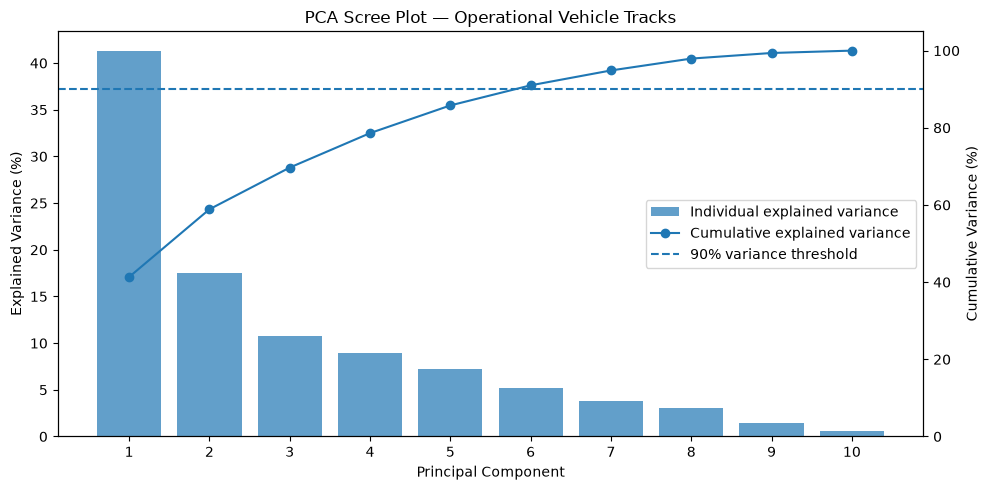

In [29]:
import matplotlib.pyplot as plt
import numpy as np

components = np.arange(1, len(pca.explained_variance_ratio_) + 1)
individual_variance = pca.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(individual_variance)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(
    components,
    individual_variance,
    alpha=0.7,
    label="Individual explained variance"
)
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained Variance (%)")
ax1.set_xticks(components)

ax2 = ax1.twinx()
ax2.plot(
    components,
    cumulative_variance,
    marker="o",
    label="Cumulative explained variance"
)
ax2.axhline(
    90,
    linestyle="--",
    label="90% variance threshold"
)
ax2.set_ylabel("Cumulative Variance (%)")
ax2.set_ylim(0, 105)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")

plt.title("PCA Scree Plot — Operational Vehicle Tracks")
plt.tight_layout()
plt.show()

In [30]:
# Step 1: Inventory available PCA representations

candidate_names = [
    "operational",
    "pca_full",
    "X_scaled",
    "X_pca",
    "X_pca_reduced",
    "X_imputed",
    "explained_variance",
    "loadings",
]

print("AVAILABLE PCA VARIABLES")
print("=" * 55)

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        print(f"{name:25s} available | shape={shape}")
    else:
        print(f"{name:25s} not found") 

AVAILABLE PCA VARIABLES
operational               available | shape=(43125, 63)
pca_full                  available | shape=(43125, 63)
X_scaled                  available | shape=(43105, 10)
X_pca                     available | shape=(43105, 10)
X_pca_reduced             available | shape=(43105, 6)
X_imputed                 available | shape=(43105, 10)
explained_variance        available | shape=(10, 4)
loadings                  available | shape=(10, 10)


In [31]:

import numpy as np
import pandas as pd

print("=" * 65)
print("1. OBJECT TYPES AND SHAPES")
print("=" * 65)

for name in ["operational", "pca_full", "X_imputed",
             "X_scaled", "X_pca", "X_pca_reduced",
             "explained_variance", "loadings"]:
    obj = globals()[name]
    print(f"{name:22s} | type={type(obj).__name__:12s} | shape={obj.shape}")

print("\n" + "=" * 65)
print("2. NUMERICAL VALIDITY")
print("=" * 65)

for name in ["X_imputed", "X_scaled", "X_pca", "X_pca_reduced"]:
    arr = np.asarray(globals()[name], dtype=float)
    print(
        f"{name:22s} | "
        f"NaNs={np.isnan(arr).sum():6d} | "
        f"Infinities={np.isinf(arr).sum():6d}"
    )

print("\n" + "=" * 65)
print("3. EXPLAINED VARIANCE")
print("=" * 65)

print(explained_variance.to_string() if isinstance(
    explained_variance, pd.DataFrame
) else explained_variance)

print("\n" + "=" * 65)
print("4. VARIANCE RETAINED")
print("=" * 65)

ev = np.asarray(X_pca, dtype=float)
if isinstance(explained_variance, pd.DataFrame):
    print("Explained-variance column names:", explained_variance.columns.tolist())
    print("Explained-variance index:", explained_variance.index.tolist())
else:
    print("Explained-variance array preview:", np.asarray(explained_variance)[:3])

# Calculate variance retained directly from the PCA scores.
component_variances = np.var(ev, axis=0, ddof=1)
variance_ratios = component_variances / component_variances.sum()
cumulative_ratios = np.cumsum(variance_ratios)

print("Variance ratios calculated from PCA scores:")
for i, (ratio, cumulative) in enumerate(
    zip(variance_ratios, cumulative_ratios), start=1
):
    print(f"PC{i:02d}: {ratio:.4%} | cumulative: {cumulative:.4%}")

print(f"\nVariance retained by 6 components: {cumulative_ratios[5]:.4%}")
print(f"All 10 components: {cumulative_ratios[-1]:.4%}")
print(f"\nSix-component shape: {np.asarray(X_pca_reduced).shape}")


1. OBJECT TYPES AND SHAPES
operational            | type=DataFrame    | shape=(43125, 63)
pca_full               | type=DataFrame    | shape=(43125, 63)
X_imputed              | type=DataFrame    | shape=(43105, 10)
X_scaled               | type=DataFrame    | shape=(43105, 10)
X_pca                  | type=ndarray      | shape=(43105, 10)
X_pca_reduced          | type=ndarray      | shape=(43105, 6)
explained_variance     | type=DataFrame    | shape=(10, 4)
loadings               | type=DataFrame    | shape=(10, 10)

2. NUMERICAL VALIDITY
X_imputed              | NaNs=     0 | Infinities=     0
X_scaled               | NaNs=     0 | Infinities=     0
X_pca                  | NaNs=     0 | Infinities=     0
X_pca_reduced          | NaNs=     0 | Infinities=     0

3. EXPLAINED VARIANCE
  Principal Component  Eigenvalue  Explained Variance (%)  Cumulative Variance (%)
0                 PC1    4.133418               41.333225                41.333225
1                 PC2    1.754822    

In [32]:

print("=" * 65)
print("1. ROW INDEX ALIGNMENT")
print("=" * 65)

print("operational index unique:", operational.index.is_unique)
print("pca_full index unique:", pca_full.index.is_unique)
print("operational and pca_full indices equal:",
      operational.index.equals(pca_full.index))

print("\nPCA-related DataFrames:")
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and (
        obj.shape[0] == 43105 or obj.shape[1] == 10
    ):
        print(f"{name:30s} shape={obj.shape}")

print("\n" + "=" * 65)
print("2. NUMERICAL VALIDITY")
print("=" * 65)

for name in ["X_imputed", "X_scaled", "X_pca", "X_pca_reduced"]:
    arr = np.asarray(globals()[name], dtype=float)
    print(
        f"{name:22s} | NaNs={np.isnan(arr).sum()} "
        f"| Infinities={np.isinf(arr).sum()}"
    )

print("\n" + "=" * 65)
print("3. PCA FEATURE DEFINITIONS")
print("=" * 65)

print("Loadings index:", loadings.index.tolist())
print("Loadings columns:", loadings.columns.tolist())
print("\nOperational columns:")
print(operational.columns.tolist())


1. ROW INDEX ALIGNMENT
operational index unique: True
pca_full index unique: True
operational and pca_full indices equal: True

PCA-related DataFrames:
X_full_pca                     shape=(43125, 10)
speed_check                    shape=(43125, 10)
X_transformed                  shape=(43125, 10)
X_pca_ready                    shape=(43105, 10)
X_imputed                      shape=(43105, 10)
X_scaled                       shape=(43105, 10)
loadings                       shape=(10, 10)
obj                            shape=(10, 10)

2. NUMERICAL VALIDITY
X_imputed              | NaNs=0 | Infinities=0
X_scaled               | NaNs=0 | Infinities=0
X_pca                  | NaNs=0 | Infinities=0
X_pca_reduced          | NaNs=0 | Infinities=0

3. PCA FEATURE DEFINITIONS
Loadings index: ['distance_km', 'duration_minutes', 'track_gap', 'raw_speed_mean_kmh', 'raw_speed_std', 'max_speed_kmh', 'd_signal_loss', 'r_signal_loss_valid', 'avg_hdop', 'raw_hdop_max']
Loadings columns: ['PC1', 'PC2', '

In [33]:

print("=" * 65)
print("1. INDEX TYPES")
print("=" * 65)

for name in ["X_full_pca", "X_transformed", "X_pca_ready",
             "X_imputed", "operational", "pca_full"]:
    obj = globals().get(name)
    if obj is not None:
        print(
            f"{name:20s} | index type={type(obj.index).__name__:12s} "
            f"| rows={len(obj)} | first indexes={list(obj.index[:5])}"
        )

print("\n" + "=" * 65)
print("2. ROWS EXCLUDED FROM PCA")
print("=" * 65)

if isinstance(X_full_pca, pd.DataFrame) and isinstance(X_pca_ready, pd.DataFrame):
    excluded_idx = X_full_pca.index.difference(X_pca_ready.index)
    print("Rows before filtering:", len(X_full_pca))
    print("Rows after filtering: ", len(X_pca_ready))
    print("Excluded row count:   ", len(excluded_idx))
    print("Excluded indexes:     ", excluded_idx.tolist()[:30])

    if len(excluded_idx) > 0:
        print("\nExcluded rows from operational data:")
        cols_to_show = [
            c for c in ["track_id", "vehicle_id", "distance_km",
                        "r_signal_loss", "r_signal_loss_valid"]
            if c in operational.columns
        ]
        print(operational.loc[excluded_idx, cols_to_show].to_string())
else:
    print("At least one PCA input object is not a DataFrame.")
    print("X_full_pca type:", type(X_full_pca))
    print("X_pca_ready type:", type(X_pca_ready))


1. INDEX TYPES
X_full_pca           | index type=Index        | rows=43125 | first indexes=[0, 1, 2, 10, 13]
X_transformed        | index type=Index        | rows=43125 | first indexes=[0, 1, 2, 10, 13]
X_pca_ready          | index type=Index        | rows=43105 | first indexes=[0, 1, 2, 10, 13]
X_imputed            | index type=Index        | rows=43105 | first indexes=[0, 1, 2, 10, 13]
operational          | index type=Index        | rows=43125 | first indexes=[0, 1, 2, 10, 13]
pca_full             | index type=Index        | rows=43125 | first indexes=[0, 1, 2, 10, 13]

2. ROWS EXCLUDED FROM PCA
Rows before filtering: 43125
Rows after filtering:  43105
Excluded row count:    20
Excluded indexes:      [28972, 39102, 49759, 64197, 84264, 87274, 88074, 103288, 103882, 116380, 116381, 117023, 118257, 118258, 129579, 129598, 133221, 138565, 145818, 147683]

Excluded rows from operational data:
        track_id  vehicle_id  distance_km  r_signal_loss  r_signal_loss_valid
28972      28972 

In [34]:

# Confirm that preprocessing preserved row order and indexes.
assert X_pca_ready.index.equals(X_imputed.index), \
    "Index mismatch: X_pca_ready vs X_imputed"

assert len(X_pca) == len(X_pca_ready), \
    "Row mismatch: PCA scores vs PCA input"

assert len(X_pca_reduced) == len(X_pca_ready), \
    "Row mismatch: reduced PCA scores vs PCA input"

assert X_pca_ready.index.is_unique, \
    "PCA input indexes are not unique"

# Attach original row indexes to the PCA scores.
pc_columns = [f"PC{i}" for i in range(1, X_pca.shape[1] + 1)]

pca_scores_df = pd.DataFrame(
    X_pca,
    index=X_pca_ready.index,
    columns=pc_columns
)

pca_scores_6_df = pca_scores_df.iloc[:, :6].copy()

# Retain track identifiers and useful operational metadata.
metadata_columns = [
    c for c in [
        "track_id", "vehicle_id", "distance_km", "duration_minutes",
        "avg_speed_kmh", "max_speed_kmh", "r_signal_loss",
        "r_signal_loss_valid"
    ]
    if c in operational.columns
]

pca_metadata = operational.loc[
    pca_scores_df.index, metadata_columns
].copy()

# Combine metadata and PCA scores using the preserved index.
pca_analysis_df = pca_metadata.join(pca_scores_df)
pca_analysis_6_df = pca_metadata.join(pca_scores_6_df)

print("PCA mapping verified.")
print("10-component dataset:", pca_analysis_df.shape)
print("6-component dataset: ", pca_analysis_6_df.shape)
print("\nFirst five mapped records:")
print(pca_analysis_6_df.head().to_string())

print("\nTrack ID alignment:",
      pca_analysis_df["track_id"].equals(
          operational.loc[pca_analysis_df.index, "track_id"]
      ))


PCA mapping verified.
10-component dataset: (43105, 18)
6-component dataset:  (43105, 14)

First five mapped records:
    track_id  vehicle_id  distance_km  duration_minutes  avg_speed_kmh  max_speed_kmh  r_signal_loss  r_signal_loss_valid       PC1       PC2       PC3       PC4       PC5       PC6
0          0           1       30.751         63.063283         29.268         74.088            0.0                  0.0 -0.253859 -1.421764  0.132911  0.271120  0.014263 -0.263679
1          1           1        7.762         15.975050         29.160         78.444            0.0                  0.0 -1.218106 -0.040360  0.969327  0.863280  0.498850  0.144820
2          2           1       19.432         44.510933         26.208         89.100            0.0                  0.0 -0.179740 -1.588983  0.126564  0.814756  0.126533  0.317060
10        10           1       10.267         12.552000         49.068         70.524            0.0                  0.0 -1.058972 -1.095606  1.071825  0

In [35]:

print("=" * 65)
print("PCA EXPERIMENT INVENTORY")
print("=" * 65)

keywords = [
    "pca", "explained", "variance", "loading",
    "feature", "operational", "telemetry"
]

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(word in name.lower() for word in keywords):
        shape = getattr(obj, "shape", None)

        if shape is not None:
            print(
                f"{name:35s} "
                f"{type(obj).__name__:15s} "
                f"shape={shape}"
            )
        elif isinstance(obj, (list, tuple, dict, set)):
            print(
                f"{name:35s} "
                f"{type(obj).__name__:15s} "
                f"length={len(obj)}"
            )


PCA EXPERIMENT INVENTORY
features                            DataFrame       shape=(151598, 63)
operational                         DataFrame       shape=(43125, 63)
candidate_features                  list            length=15
pca_source                          DataFrame       shape=(43125, 70)
pca_candidates                      list            length=7
pca_audit                           DataFrame       shape=(7, 4)
operational_features                list            length=5
telemetry_features                  list            length=2
all_pca_features                    list            length=7
pca_data                            DataFrame       shape=(42867, 7)
X_operational                       DataFrame       shape=(42867, 5)
X_telemetry                         DataFrame       shape=(42867, 7)
Z_operational                       ndarray         shape=(42867, 5)
Z_telemetry                         ndarray         shape=(42867, 7)
scores_operational                  ndarray     

In [36]:

print("=" * 70)
print("1. FEATURE DEFINITIONS")
print("=" * 70)

print("Operational PCA features:")
print(operational_features)

print("\nTelemetry-aware PCA features:")
print(all_pca_features)

print("\n10-feature PCA features:")
print(selected_features)

print("\n" + "=" * 70)
print("2. EXPLAINED VARIANCE COMPARISON")
print("=" * 70)

print("\nOperational PCA:")
print(variance_operational.to_string(index=False))

print("\nTelemetry-aware PCA:")
print(variance_telemetry.to_string(index=False))

print("\n10-feature PCA:")
print(explained_variance.to_string(index=False))

print("\n" + "=" * 70)
print("3. TRACK INDEX COMPARISON")
print("=" * 70)

print("pca_data index unique:", pca_data.index.is_unique)
print("X_pca_ready index unique:", X_pca_ready.index.is_unique)

print("5-feature and 7-feature PCA share same rows:",
      X_operational.index.equals(X_telemetry.index))

print("7-feature PCA row count:", len(X_telemetry))
print("10-feature PCA row count:", len(X_pca_ready))

common_idx = X_telemetry.index.intersection(X_pca_ready.index)

print("Common row count:", len(common_idx))
print("Common rows equal to 7-feature rows:",
      len(common_idx) == len(X_telemetry))
print("Common rows equal to 10-feature rows:",
      len(common_idx) == len(X_pca_ready))


1. FEATURE DEFINITIONS
Operational PCA features:
['distance_log', 'duration_log', 'raw_speed_mean_kmh', 'max_speed_kmh', 'avg_speed_kmh_for_pca']

Telemetry-aware PCA features:
['distance_log', 'duration_log', 'raw_speed_mean_kmh', 'max_speed_kmh', 'avg_speed_kmh_for_pca', 'd_signal_loss_log', 'r_signal_loss_for_pca']

10-feature PCA features:
['distance_km', 'duration_minutes', 'track_gap', 'raw_speed_mean_kmh', 'raw_speed_std', 'max_speed_kmh', 'd_signal_loss', 'r_signal_loss_valid', 'avg_hdop', 'raw_hdop_max']

2. EXPLAINED VARIANCE COMPARISON

Operational PCA:
component  explained_variance_ratio  explained_variance_percent  cumulative_variance_percent  experiment
      PC1                  0.808866                   80.886580                    80.886580 Operational
      PC2                  0.105022                   10.502238                    91.388818 Operational
      PC3                  0.066341                    6.634090                    98.022908 Operational
      PC4

In [37]:

# Use the 42,867 tracks from the earlier PCA experiments.
common_idx = X_telemetry.index.intersection(pca_scores_df.index)

assert len(common_idx) == 42867
assert X_operational.index.equals(X_telemetry.index)

# Wrap the older score arrays with their original track indexes.
scores_operational_df = pd.DataFrame(
    scores_operational,
    index=X_operational.index,
    columns=[f"PC{i}" for i in range(1, scores_operational.shape[1] + 1)]
)

scores_telemetry_df = pd.DataFrame(
    scores_telemetry,
    index=X_telemetry.index,
    columns=[f"PC{i}" for i in range(1, scores_telemetry.shape[1] + 1)]
)

# Restrict every representation to exactly the same track rows.
X_pca_5_common = scores_operational_df.loc[common_idx].copy()
X_pca_7_common = scores_telemetry_df.loc[common_idx].copy()
X_pca_10_common = pca_scores_df.loc[common_idx].copy()

# Confirm alignment and dimensions.
print("Common tracks:", len(common_idx))
print("5-feature PCA scores:", X_pca_5_common.shape)
print("7-feature PCA scores:", X_pca_7_common.shape)
print("10-feature PCA scores:", X_pca_10_common.shape)

print("\nIndex alignment checks:")
print("5 vs 7:", X_pca_5_common.index.equals(X_pca_7_common.index))
print("7 vs 10:", X_pca_7_common.index.equals(X_pca_10_common.index))

print("\nMissing values:")
for name, df in [
    ("5-feature PCA", X_pca_5_common),
    ("7-feature PCA", X_pca_7_common),
    ("10-feature PCA", X_pca_10_common),
]:
    print(f"{name}: {df.isna().sum().sum()}")


Common tracks: 42867
5-feature PCA scores: (42867, 5)
7-feature PCA scores: (42867, 7)
10-feature PCA scores: (42867, 10)

Index alignment checks:
5 vs 7: True
7 vs 10: True

Missing values:
5-feature PCA: 0
7-feature PCA: 0
10-feature PCA: 0


In [38]:

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Fit the 5-feature PCA on the common tracks.
pca_common_5 = PCA()
scores_common_5 = pca_common_5.fit_transform(Z_operational)

# 2. Fit the 7-feature PCA on the same common tracks.
pca_common_7 = PCA()
scores_common_7 = pca_common_7.fit_transform(Z_telemetry)

# 3. Refit preprocessing and PCA for the 10-feature experiment.
X_10_common = X_pca_ready.loc[common_idx].copy()

imputer_common_10 = SimpleImputer(strategy="median")
X_10_imputed_common = imputer_common_10.fit_transform(X_10_common)

scaler_common_10 = StandardScaler()
X_10_scaled_common = scaler_common_10.fit_transform(
    X_10_imputed_common
)

pca_common_10 = PCA()
scores_common_10 = pca_common_10.fit_transform(
    X_10_scaled_common
)

# Build consistently indexed score DataFrames.
pca_common_5_df = pd.DataFrame(
    scores_common_5,
    index=common_idx,
    columns=[f"PC{i}" for i in range(1, 6)]
)

pca_common_7_df = pd.DataFrame(
    scores_common_7,
    index=common_idx,
    columns=[f"PC{i}" for i in range(1, 8)]
)

pca_common_10_df = pd.DataFrame(
    scores_common_10,
    index=common_idx,
    columns=[f"PC{i}" for i in range(1, 11)]
)

# Report variance retained by each representation.
for name, model, scores in [
    ("5-feature PCA", pca_common_5, pca_common_5_df),
    ("7-feature PCA", pca_common_7, pca_common_7_df),
    ("10-feature PCA", pca_common_10, pca_common_10_df),
]:
    cumulative = np.cumsum(model.explained_variance_ratio_)
    n90 = np.searchsorted(cumulative, 0.90) + 1

    print(f"\n{name}")
    print("-" * 45)
    print("Tracks:", len(scores))
    print("Components:", scores.shape[1])
    print(f"Variance retained by all PCs: {cumulative[-1]:.4%}")
    print(f"Components needed for >=90%: {n90}")
    print(f"Variance at {n90} components: {cumulative[n90 - 1]:.4%}")
    print("All scores finite:", np.isfinite(scores.to_numpy()).all())

print("\nIndex alignment:")
print("5 vs 7:", pca_common_5_df.index.equals(pca_common_7_df.index))
print("7 vs 10:", pca_common_7_df.index.equals(pca_common_10_df.index))



5-feature PCA
---------------------------------------------
Tracks: 42867
Components: 5
Variance retained by all PCs: 100.0000%
Components needed for >=90%: 2
Variance at 2 components: 91.3888%
All scores finite: True

7-feature PCA
---------------------------------------------
Tracks: 42867
Components: 7
Variance retained by all PCs: 100.0000%
Components needed for >=90%: 4
Variance at 4 components: 94.6076%
All scores finite: True

10-feature PCA
---------------------------------------------
Tracks: 42867
Components: 10
Variance retained by all PCs: 100.0000%
Components needed for >=90%: 6
Variance at 6 components: 91.1321%
All scores finite: True

Index alignment:
5 vs 7: True
7 vs 10: True


In [39]:

def show_top_loadings(model, feature_names, n_components, model_name):
    loading_matrix = pd.DataFrame(
        model.components_[:n_components].T,
        index=feature_names,
        columns=[f"PC{i}" for i in range(1, n_components + 1)]
    )

    print(f"\n{model_name}")
    print("-" * 65)

    for pc in loading_matrix.columns:
        top = loading_matrix[pc].abs().sort_values(ascending=False).head(3)
        print(f"\n{pc}:")
        for feature in top.index:
            print(f"  {feature:30s} loading={loading_matrix.loc[feature, pc]:+.4f}")

# Feature order must match the exact matrices used to fit each PCA.
features_5 = list(operational_features)
features_7 = list(all_pca_features)
features_10 = list(X_10_common.columns)

show_top_loadings(
    pca_common_5, features_5, 2, "5-feature Operational PCA"
)

show_top_loadings(
    pca_common_7, features_7, 4, "7-feature Operational + Telemetry PCA"
)

show_top_loadings(
    pca_common_10, features_10, 6, "10-feature Broader Telemetry PCA"
)



5-feature Operational PCA
-----------------------------------------------------------------

PC1:
  distance_log                   loading=+0.4839
  raw_speed_mean_kmh             loading=+0.4672
  avg_speed_kmh_for_pca          loading=+0.4581

PC2:
  duration_log                   loading=+0.8120
  avg_speed_kmh_for_pca          loading=-0.3627
  raw_speed_mean_kmh             loading=-0.3126

7-feature Operational + Telemetry PCA
-----------------------------------------------------------------

PC1:
  distance_log                   loading=+0.4629
  raw_speed_mean_kmh             loading=+0.4430
  avg_speed_kmh_for_pca          loading=+0.4353

PC2:
  r_signal_loss_for_pca          loading=+0.8407
  d_signal_loss_log              loading=+0.4989
  avg_speed_kmh_for_pca          loading=-0.1326

PC3:
  duration_log                   loading=+0.5702
  d_signal_loss_log              loading=+0.4635
  max_speed_kmh                  loading=-0.4369

PC4:
  duration_log                 

In [40]:

# Retain the number of PCs required to explain at least 90% variance.
X_cluster_5 = pca_common_5_df.iloc[:, :2].copy()
X_cluster_7 = pca_common_7_df.iloc[:, :4].copy()
X_cluster_10 = pca_common_10_df.iloc[:, :6].copy()

candidates = {
    "Operational PCA (2 PCs)": X_cluster_5,
    "Operational + telemetry PCA (4 PCs)": X_cluster_7,
    "Broader telemetry PCA (6 PCs)": X_cluster_10,
}

print("CLUSTERING CANDIDATES")
print("=" * 65)

for name, X in candidates.items():
    print(f"\n{name}")
    print("Shape:", X.shape)
    print("Index unique:", X.index.is_unique)
    print("Contains missing values:", X.isna().any().any())
    print("All values finite:", np.isfinite(X.to_numpy()).all())

# Verify that every candidate uses the same tracks.
candidate_indexes = [X.index for X in candidates.values()]

assert all(
    candidate_indexes[0].equals(idx)
    for idx in candidate_indexes[1:]
), "Candidate matrices do not have identical track indexes."

print("\nAll candidates use the same tracks and index order.")


CLUSTERING CANDIDATES

Operational PCA (2 PCs)
Shape: (42867, 2)
Index unique: True
Contains missing values: False
All values finite: True

Operational + telemetry PCA (4 PCs)
Shape: (42867, 4)
Index unique: True
Contains missing values: False
All values finite: True

Broader telemetry PCA (6 PCs)
Shape: (42867, 6)
Index unique: True
Contains missing values: False
All values finite: True

All candidates use the same tracks and index order.


In [41]:

# Reduced representations
X_cluster_5 = pca_common_5_df.iloc[:, :2].copy()
X_cluster_7 = pca_common_7_df.iloc[:, :4].copy()
X_cluster_10 = pca_common_10_df.iloc[:, :6].copy()

# Full representations
X_cluster_5_full = pca_common_5_df.copy()
X_cluster_7_full = pca_common_7_df.copy()
X_cluster_10_full = pca_common_10_df.copy()

candidates = {
    "Operational_2PC": X_cluster_5,
    "Operational_5PC": X_cluster_5_full,
    "Telemetry_4PC": X_cluster_7,
    "Telemetry_7PC": X_cluster_7_full,
    "Broad_6PC": X_cluster_10,
    "Broad_10PC": X_cluster_10_full,
}

print("Candidate | Shape | Finite | Index aligned")
print("-" * 65)

for name, X in candidates.items():
    print(
        f"{name:20s} | {str(X.shape):14s} | "
        f"{np.isfinite(X.to_numpy()).all()} | "
        f"{X.index.equals(common_idx)}"
    )

assert all(
    X.index.equals(common_idx) for X in candidates.values()
), "Candidate row alignment failed."

assert all(
    np.isfinite(X.to_numpy()).all() for X in candidates.values()
), "Non-finite values found."

print("\nAll six candidates are ready.")


Candidate | Shape | Finite | Index aligned
-----------------------------------------------------------------
Operational_2PC      | (42867, 2)     | True | True
Operational_5PC      | (42867, 5)     | True | True
Telemetry_4PC        | (42867, 4)     | True | True
Telemetry_7PC        | (42867, 7)     | True | True
Broad_6PC            | (42867, 6)     | True | True
Broad_10PC           | (42867, 10)    | True | True

All six candidates are ready.


In [42]:
import pandas as pd
import numpy as np

def display_loadings(name, feature_names, loading_matrix):
    loading_df = pd.DataFrame(
        loading_matrix,
        index=feature_names,
        columns=[
            f"PC{i+1}"
            for i in range(loading_matrix.shape[1])
        ]
    )

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    # Sort features by absolute loading on each component
    for pc in loading_df.columns:
        print(f"\n{pc} — strongest feature contributions:")
        print(
            loading_df[pc]
            .sort_values(key=abs, ascending=False)
            .round(4)
            .to_string()
        )

    return loading_df


# 1. Operational PCA: 5 features
loadings_5_df = display_loadings(
    "OPERATIONAL PCA — 5 FEATURES",
    operational_features,
    loadings_operational
)

# 2. Operational + telemetry PCA: 7 features
loadings_7_df = display_loadings(
    "OPERATIONAL + TELEMETRY PCA — 7 FEATURES",
    all_pca_features,
    loadings_telemetry
)

# 3. Broad PCA: 10 features, refitted on the common 42,867 tracks
# Use the fitted PCA estimator from the common-row experiment.
loadings_10_common = pca_common_10.components_.T

loadings_10_df = display_loadings(
    "BROAD PCA — 10 FEATURES (COMMON-ROW REFIT)",
    selected_features,
    loadings_10_common
)


OPERATIONAL PCA — 5 FEATURES

PC1 — strongest feature contributions:
distance_log             0.4839
raw_speed_mean_kmh       0.4672
avg_speed_kmh_for_pca    0.4581
max_speed_kmh            0.4214
duration_log             0.4002

PC2 — strongest feature contributions:
duration_log             0.8120
avg_speed_kmh_for_pca   -0.3627
raw_speed_mean_kmh      -0.3126
max_speed_kmh           -0.2642
distance_log             0.2038

PC3 — strongest feature contributions:
max_speed_kmh            0.8585
avg_speed_kmh_for_pca   -0.4359
raw_speed_mean_kmh      -0.2396
distance_log            -0.1228
duration_log             0.0232

PC4 — strongest feature contributions:
raw_speed_mean_kmh       0.7598
distance_log            -0.4586
avg_speed_kmh_for_pca   -0.4078
duration_log             0.2040
max_speed_kmh           -0.0661

PC5 — strongest feature contributions:
distance_log             0.7064
avg_speed_kmh_for_pca   -0.5497
duration_log            -0.3720
raw_speed_mean_kmh       0.2219
ma

### PCA Loading Interpretation and Validation — 18 October 2026

**Objective:** Interpret the principal components of the operational, operational-plus-telemetry, and broad telemetry feature sets using a common sample of 42,867 tracks.

**Operational PCA (5 features):**
- The first principal component is dominated by distance and speed-related features and represents broad operational variation.
- The second component is primarily associated with duration, contrasting it with speed-related variation.
- Later components retain more specific distinctions involving maximum speed, raw mean speed, and distance versus average speed.
- Two PCs retain 91.39% of the variance.

**Operational + telemetry PCA (7 features):**
- PC1 continues to capture broad operational variation.
- PC2 is dominated by the signal-loss ratio and signal-loss distance, indicating an additional telemetry-related dimension.
- Later components capture mixed duration, signal-loss, and speed-specific patterns.
- Four PCs retain 94.61% of the variance.

**Broad PCA (10 features):**
- PC1 captures broad operational variation.
- PC2 emphasizes GPS/telemetry quality and signal loss.
- PC3–PC7 capture additional contrasts involving track gaps, signal-loss measures, speed variability, and HDOP.
- PC8–PC10 preserve further speed- and distance-related distinctions.
- Six PCs retain 91.13% of the variance on the common sample.

**Conclusions:**
1. The three feature sets capture different combinations of operational and telemetry information.
2. Adding telemetry features introduces distinct dimensions that are not prominent in the operational-only PCA.
3. Reduced PCA representations are compact, but discarded components may still contain useful clustering information.
4. Explained variance alone cannot determine the best clustering representation.
5. Telemetry-quality features may influence clustering and must be considered when interpreting the resulting groups.
6. PCA component interpretations are provisional and do not establish causal relationships or operational cluster labels.

**Next step:** On 19 October, define and document the candidate feature representations and comparison hypotheses before conducting the scheduled clustering baselines.

In [43]:

from pathlib import Path

# Current working directory is notebooks/
PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "pca_clustering_inputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pca_outputs = {
    "Operational_2PC": X_cluster_5,
    "Operational_5PC": X_cluster_5_full,
    "Telemetry_4PC": X_cluster_7,
    "Telemetry_7PC": X_cluster_7_full,
    "Broad_6PC": X_cluster_10,
    "Broad_10PC": X_cluster_10_full,
}

for name, df in pca_outputs.items():
    path = OUTPUT_DIR / f"{name}.parquet"
    df.to_parquet(path, index=True)
    print(f"{name:20} | {df.shape} | Saved: {path.name}")

# Save the shared track index separately.
common_idx_df = pd.DataFrame({"track_index": common_idx})
common_idx_df.to_parquet(
    OUTPUT_DIR / "common_track_index.parquet",
    index=False
)

print("\nTotal files:", len(list(OUTPUT_DIR.glob("*.parquet"))))
print("Output folder:", OUTPUT_DIR)


Operational_2PC      | (42867, 2) | Saved: Operational_2PC.parquet
Operational_5PC      | (42867, 5) | Saved: Operational_5PC.parquet
Telemetry_4PC        | (42867, 4) | Saved: Telemetry_4PC.parquet
Telemetry_7PC        | (42867, 7) | Saved: Telemetry_7PC.parquet
Broad_6PC            | (42867, 6) | Saved: Broad_6PC.parquet
Broad_10PC           | (42867, 10) | Saved: Broad_10PC.parquet

Total files: 7
Output folder: /Users/janibhargesh/Documents/ML-Project/data/processed/pca_clustering_inputs


In [44]:

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "pca_clustering_inputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Original standardized inputs, using the same 42,867 tracks
original_outputs = {
    "Operational_Original": pd.DataFrame(
        Z_operational,
        index=common_idx,
        columns=operational_features
    ),
    "Telemetry_Original": pd.DataFrame(
        Z_telemetry,
        index=common_idx,
        columns=all_pca_features
    ),
    "Broad_Original": pd.DataFrame(
        X_10_scaled_common,
        index=common_idx,
        columns=X_10_common.columns
    ),
}

# Validate and save
for name, df in original_outputs.items():
    assert len(df) == 42867, f"{name}: unexpected row count"
    assert df.index.equals(common_idx), f"{name}: index mismatch"
    assert np.isfinite(df.to_numpy()).all(), f"{name}: non-finite values"

    path = OUTPUT_DIR / f"{name}.parquet"
    df.to_parquet(path, index=True)

    print(f"{name:25} | {df.shape} | Saved: {path.name}")

print("\nOriginal feature matrices saved successfully.")


Operational_Original      | (42867, 5) | Saved: Operational_Original.parquet
Telemetry_Original        | (42867, 7) | Saved: Telemetry_Original.parquet
Broad_Original            | (42867, 10) | Saved: Broad_Original.parquet

Original feature matrices saved successfully.
